# 06 · Opposition EDA

**Question: how does Barcelona's profile compare with the next opponent's?**

Barcelona cannot be modelled in isolation: a 2-0 against the bottom side and
a 2-0 at the Bernabéu are different pieces of evidence. This notebook:

1. maps the whole league in 2015/16, the one season with every club's
   events;
2. measures **how opponents change their game against Barcelona**;
3. builds the first **relative** statistics and checks whether they separate
   results:

$$ AttackDiff = BarcaAttack - OpponentDefence $$
$$ FormDiff = BarcaForm - OpponentForm $$
$$ xGDiff = BarcaRollingxG - OpponentRollingxGA $$

Opponent form and strength come from football-data (complete for every
club, every season). Opponent *event* profiles only exist for 2015/16 and
for matches against Barcelona (notebook 01).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import polars as pl

from barca import config, pipeline
from barca.analytics import results as res
from barca.analytics import team_match
from barca.data import normalize
from barca.features import rolling
from barca.visualization import style

style.apply()
pl.Config.set_tbl_rows(25)
pl.Config.set_tbl_width_chars(170)
pl.Config.set_tbl_hide_dataframe_shape(True)
pl.Config.set_float_precision(2)

matches = normalize.matches(pl.read_parquet(config.INTERIM / "matches.parquet"))
events = normalize.events(pipeline.scan_events())
tms = team_match.team_match_stats(events, matches)
teams = normalize.team_reference()

## 1. The league in 2015/16

Chance creation and prevention for all 20 clubs.

In [2]:
lg = (
    tms.filter(pl.col("season") == "2015/2016")
    .group_by("team")
    .agg(
        pl.len().alias("matches"),
        pl.col("points").sum().alias("points"),
        pl.col("xg").mean().alias("xg"),
        pl.col("xga").mean().alias("xga"),
        pl.col("possession").mean().alias("possession"),
        pl.col("ppda").mean().alias("ppda"),
        pl.col("field_tilt").mean().alias("field_tilt"),
        pl.col("defensive_action_height").mean().alias("def_height"),
        pl.col("progressive_passes").mean().alias("prog_passes"),
    )
    .sort("points", descending=True)
)
lg

team,matches,points,xg,xga,possession,ppda,field_tilt,def_height,prog_passes
str,u32,i64,f32,f32,f64,f64,f64,f32,f64
"""Barcelona""",38,91,2.41,0.86,0.66,12.01,0.70,53.72,96.45
"""Real Madrid""",38,90,2.13,1.17,0.57,14.22,0.60,51.14,88.00
"""Atlético Madrid""",38,88,1.39,0.68,0.49,13.82,0.57,52.28,60.50
"""Villarreal""",38,64,0.98,1.05,0.46,14.98,0.44,48.91,57.13
"""Athletic Club""",38,62,1.32,1.07,0.50,14.04,0.54,52.71,59.42
"""Celta Vigo""",38,60,1.32,1.31,0.56,11.16,0.54,48.95,70.84
"""Sevilla""",38,52,1.60,1.19,0.50,13.64,0.50,49.93,55.66
"""Real Sociedad""",38,48,1.21,1.21,0.52,13.11,0.56,51.47,63.55
"""Málaga""",38,48,1.14,1.13,0.48,12.72,0.51,50.55,51.21


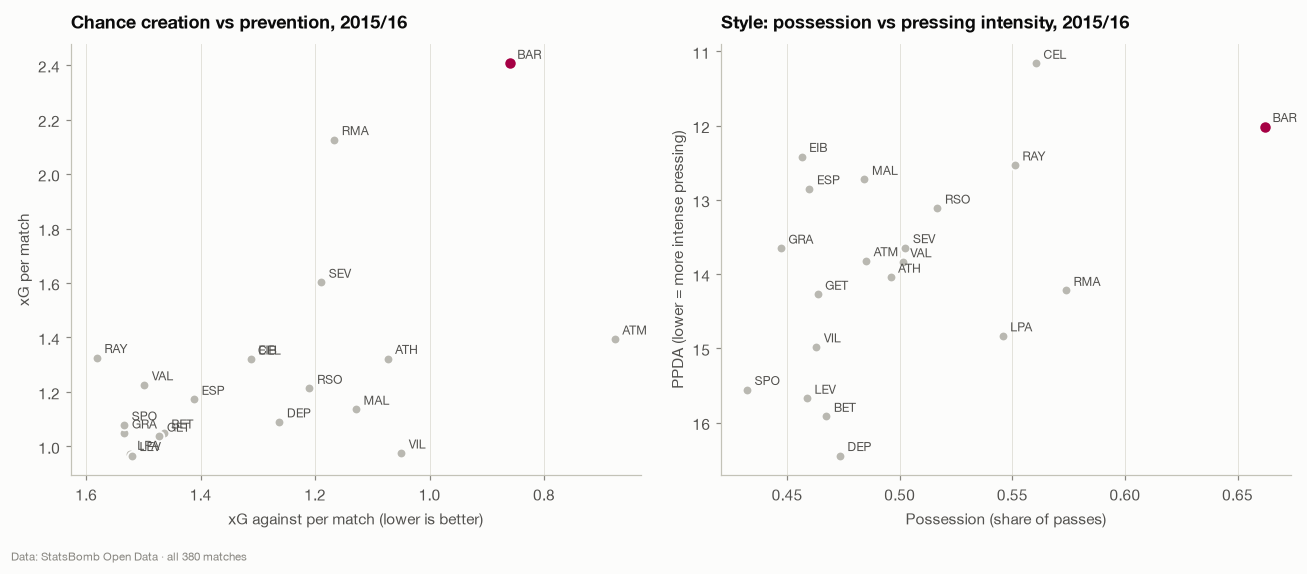

In [3]:
code = dict(zip(teams["name"], teams["code"], strict=True))
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
ax = axes[0]
others = lg.filter(pl.col("team") != "Barcelona")
ax.scatter(others["xga"], others["xg"], s=40, color=style.NEUTRAL, edgecolor=style.SURFACE, linewidth=1.2)
b = lg.filter(pl.col("team") == "Barcelona")
ax.scatter(b["xga"], b["xg"], s=70, color=style.BARCA, edgecolor=style.SURFACE, linewidth=1.5, zorder=3)
for r in lg.iter_rows(named=True):
    ax.annotate(code.get(r["team"], r["team"][:3].upper()), (r["xga"], r["xg"]), xytext=(5, 3),
                textcoords="offset points", fontsize=8, color=style.INK_2)
ax.invert_xaxis()
ax.set_xlabel("xG against per match (lower is better)")
ax.set_ylabel("xG per match")
ax.set_title("Chance creation vs prevention, 2015/16")
ax.grid(axis="both")

ax = axes[1]
ax.scatter(others["possession"], others["ppda"], s=40, color=style.NEUTRAL, edgecolor=style.SURFACE, linewidth=1.2)
ax.scatter(b["possession"], b["ppda"], s=70, color=style.BARCA, edgecolor=style.SURFACE, linewidth=1.5, zorder=3)
for r in lg.iter_rows(named=True):
    ax.annotate(code.get(r["team"], r["team"][:3].upper()), (r["possession"], r["ppda"]), xytext=(5, 3),
                textcoords="offset points", fontsize=8, color=style.INK_2)
ax.invert_yaxis()
ax.set_xlabel("Possession (share of passes)")
ax.set_ylabel("PPDA (lower = more intense pressing)")
ax.set_title("Style: possession vs pressing intensity, 2015/16")
ax.grid(axis="both")
style.caption(axes[0], style.STATSBOMB_CREDIT + " · all 380 matches")
fig.tight_layout()
style.savefig(fig, "06_league_2015_16")
plt.show()

Barcelona and Real Madrid are in a class of their own for chance creation.
Atlético's defence stands out: the lowest xG against in the league with far
less of the ball. The style panel separates **possession-and-press** sides
(Barcelona top-right) from **deep, reactive** ones (low possession, high
PPDA). The same match-level metrics can describe any upcoming opponent in
2015/16. For other seasons the opponent's profile has to be built from
their matches against Barcelona and from football-data results.

## 2. How opponents change against Barcelona

For every 2015/16 club: their average against Barcelona minus their
average against everyone else.

In [4]:
s1516 = tms.filter(pl.col("season") == "2015/2016", pl.col("team") != "Barcelona").with_columns(
    (pl.col("opponent") == "Barcelona").alias("vs_barca")
)
shift = (
    s1516.group_by("team", "vs_barca")
    .agg(
        pl.col("possession").mean(), pl.col("defensive_action_height").mean(),
        pl.col("ppda").mean(), pl.col("xg").mean(), pl.col("pressures").mean(),
    )
    .pivot(on="vs_barca", index="team")
)
delta = shift.select(
    "team",
    ((pl.col("possession_true") - pl.col("possession_false")) * 100).alias("possession_pp"),
    (pl.col("defensive_action_height_true") - pl.col("defensive_action_height_false")).alias("def_height_yards"),
    (pl.col("ppda_true") - pl.col("ppda_false")).alias("ppda"),
    (pl.col("xg_true") - pl.col("xg_false")).alias("xg"),
).sort("def_height_yards")
delta

team,possession_pp,def_height_yards,ppda,xg
str,f64,f32,f64,f32
"""Getafe""",-16.28,-8.71,13.40,-0.83
"""Real Betis""",-15.77,-5.93,15.23,-0.43
"""Atlético Madrid""",-18.55,-5.88,3.67,-0.74
"""Valencia""",-21.01,-5.78,10.41,-0.69
"""Sporting Gijón""",-18.95,-5.63,16.01,-0.62
"""Levante""",-14.88,-5.44,2.24,-0.19
"""Sevilla""",-16.55,-5.07,2.39,-0.21
"""Espanyol""",-15.67,-5.00,1.89,-0.86
"""Málaga""",-18.63,-4.93,2.23,-0.40


In [5]:
summary = delta.select(
    pl.col("possession_pp").mean(), pl.col("def_height_yards").mean(), pl.col("ppda").mean(), pl.col("xg").mean(),
    (pl.col("def_height_yards") < 0).sum().alias("teams_deeper"),
)
summary

possession_pp,def_height_yards,ppda,xg,teams_deeper
f64,f32,f64,f32,u32
-16.21,-3.17,8.00,-0.39,15


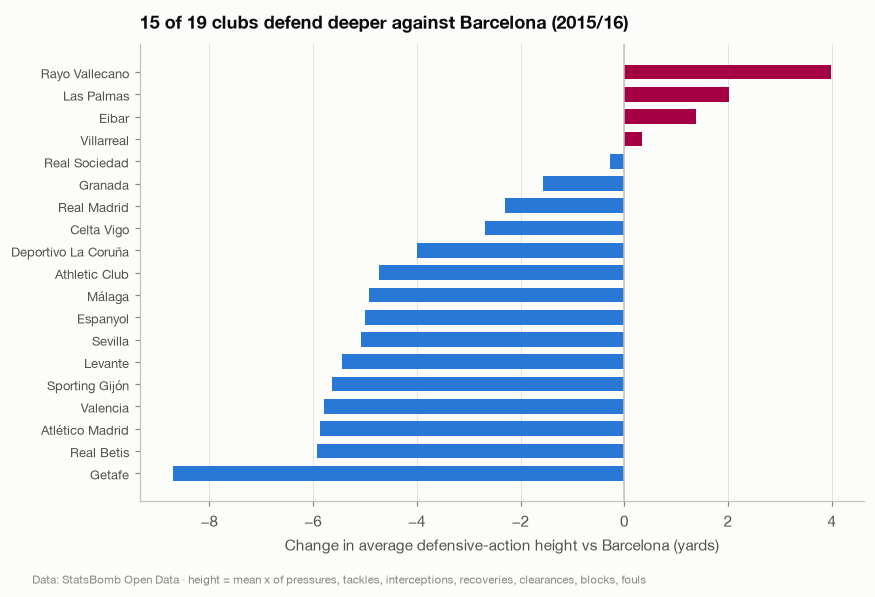

In [6]:
fig, ax = plt.subplots(figsize=(8.5, 5.4))
d = delta.sort("def_height_yards")
y = np.arange(d.height)
ax.barh(y, d["def_height_yards"], color=[style.OPPONENT if v < 0 else style.BARCA for v in d["def_height_yards"]],
        height=0.66)
ax.set_yticks(y, d["team"].to_list(), fontsize=8.5)
ax.axvline(0, color=style.AXIS, lw=1)
ax.set_xlabel("Change in average defensive-action height vs Barcelona (yards)")
ax.set_title("15 of 19 clubs defend deeper against Barcelona (2015/16)")
ax.grid(axis="x")
ax.grid(axis="y", visible=False)
style.caption(ax, style.STATSBOMB_CREDIT + " · height = mean x of pressures, tackles, interceptions, recoveries, clearances, blocks, fouls")
style.savefig(fig, "06_opponents_deeper")
plt.show()

Against Barcelona, clubs give up about 16 points of possession, defend about
3 yards deeper on average (15 of 19 clubs), press less (PPDA up by ~8)
and create about 0.4 xG less than in their other matches. This is the
low block Barcelona faced every week. It also means an opponent's
*general* profile overstates what it will do in this fixture, so the model
should prefer results-based strength (Elo, form) and treat event-style
features for the opponent carefully.

Is this constant over time? Opponents' average possession and block height
in all Barcelona matches, by season:

In [7]:
vs = (
    tms.filter(pl.col("opponent") == "Barcelona", pl.col("competition") == "La Liga")
    .group_by("season")
    .agg(pl.len().alias("n"), pl.col("possession").mean().alias("opp_possession"),
         pl.col("defensive_action_height").mean().alias("opp_def_height"),
         pl.col("ppda").mean().alias("opp_ppda"), pl.col("xg").mean().alias("opp_xg"))
    .sort("season")
)
vs

season,n,opp_possession,opp_def_height,opp_ppda,opp_xg
str,u32,f64,f32,f64,f32
"""2004/2005""",7,0.37,43.80,17.41,0.52
"""2005/2006""",17,0.40,44.94,14.08,0.74
"""2006/2007""",26,0.36,47.71,18.15,0.87
"""2007/2008""",27,0.38,47.59,17.68,0.96
"""2008/2009""",31,0.35,43.81,17.49,0.62
"""2009/2010""",35,0.34,48.78,18.63,0.76
"""2010/2011""",33,0.29,46.40,22.26,0.70
"""2011/2012""",37,0.31,46.01,20.73,0.75
"""2012/2013""",32,0.32,47.85,22.03,0.91


Opponents' possession against Barcelona stays in a 29-40% band for the
whole period, so the low-block problem is structural, not a phase. There is
one drift: from 2017/18 opponents defended slightly higher (≈48-50 yards
against ≈44-48 before) and their xG against Barcelona rose to ≈1.0 a match.
Later opponents were bolder, and it paid off. That matches the defensive
decline seen in notebook 02.

## 3. Relative statistics

Form and attack/defence strength for **every club** from the complete
football-data results, computed with the leak-free rolling helpers
(`barca.features.rolling`): each value uses only matches *before* the one
being described.

In [8]:
fd = normalize.football_data_results(pl.read_parquet(config.INTERIM / "football_data.parquet"))
long = res.long_results(fd)
long = rolling.add_rolling_means(
    long, by="team", order=["date", "fixture_id"], cols=["points", "goals", "goals_against", "shots", "sot"],
    windows=[5, 10],
)
own = long.select("fixture_id", "team", "date", "season", "is_home", "opponent", "result",
                  "points_5", "points_10", "goals_10", "goals_against_10", "sot_10")
opp = long.select("fixture_id", pl.col("team").alias("opponent"),
                  pl.col("points_5").alias("opp_points_5"), pl.col("points_10").alias("opp_points_10"),
                  pl.col("goals_10").alias("opp_goals_10"), pl.col("goals_against_10").alias("opp_goals_against_10"))
rel = own.join(opp, on=["fixture_id", "opponent"]).with_columns(
    (pl.col("points_5") - pl.col("opp_points_5")).alias("form_diff"),
    # literal reading of the plan: own attack minus opponent's goals conceded
    (pl.col("goals_10") - pl.col("opp_goals_against_10")).alias("attack_diff_literal"),
    # sign-consistent version: both sides as "higher = stronger"
    ((pl.col("goals_10") - pl.col("goals_against_10")) - (pl.col("opp_goals_10") - pl.col("opp_goals_against_10")))
    .alias("strength_diff"),
)
barca_rel = rel.filter(pl.col("team") == "Barcelona", pl.col("season").str.slice(0, 4).cast(pl.Int32) >= 2004).drop_nulls("form_diff")
print(f"Barcelona league matches with relative features: {barca_rel.height}")

Barcelona league matches with relative features: 646


In [9]:
def outcome_by_bucket(frame: pl.DataFrame, col: str, q: int = 4) -> pl.DataFrame:
    return (
        frame.with_columns(pl.col(col).qcut(q, labels=[f"Q{i + 1}" for i in range(q)]).alias("bucket"))
        .group_by("bucket")
        .agg(
            pl.len().alias("n"),
            pl.col(col).mean().alias(f"mean_{col}"),
            (pl.col("result") == "W").mean().alias("win"),
            (pl.col("result") == "D").mean().alias("draw"),
            (pl.col("result") == "L").mean().alias("loss"),
        )
        .sort("bucket")
    )


outcome_by_bucket(barca_rel, "form_diff")

bucket,n,mean_form_diff,win,draw,loss
cat,u32,f64,f64,f64,f64
"""Q1""",186,-0.08,0.60,0.23,0.17
"""Q2""",186,0.76,0.74,0.18,0.09
"""Q3""",149,1.37,0.72,0.16,0.11
"""Q4""",125,2.05,0.79,0.14,0.06


In [10]:
outcome_by_bucket(barca_rel, "attack_diff_literal")

bucket,n,mean_attack_diff_literal,win,draw,loss
cat,u32,f64,f64,f64,f64
"""Q1""",164,0.40,0.70,0.20,0.10
"""Q2""",167,1.01,0.71,0.16,0.13
"""Q3""",163,1.48,0.69,0.20,0.12
"""Q4""",152,2.18,0.73,0.16,0.11


**FormDiff works**: Barcelona win 79% of matches in the top quartile against
60% in the bottom one, where the opponent's recent form matches theirs, and
draws and losses pile up there.

**The literal AttackDiff does not.** Win rates are flat across its
quartiles. The reason is a sign problem hidden in the formula: goals
conceded is a "higher = *worse*" measure of defence, so subtracting it
*rewards* facing a strong defence. Both sides of a relative feature have to
point the same way. Expressing each team's strength as "higher = better"
(goal difference per match) gives a proper strength difference:

$$ StrengthDiff = (GF - GA)_{Barça} - (GF - GA)_{Opp} $$

and, for chance volume in the specific fixture, the matchup terms
$BarcaAttack + OpponentGoalsConceded$ and
$BarcaGoalsConceded + OpponentAttack$ (used as features in notebook 09).

In [11]:
outcome_by_bucket(barca_rel, "strength_diff")

bucket,n,mean_strength_diff,win,draw,loss
cat,u32,f64,f64,f64,f64
"""Q1""",172,0.44,0.59,0.24,0.17
"""Q2""",154,1.38,0.71,0.18,0.11
"""Q3""",162,2.01,0.74,0.17,0.09
"""Q4""",158,2.94,0.80,0.13,0.08


With consistent signs the separation appears: Barcelona's win rate rises
from 59% to 80% across the quartiles, and losses halve. Every relative feature in the project follows
the same convention.

### xG-based: $xGDiff = BarcaRollingxG - OpponentRollingxGA$

An xG version is only possible where the opponent's previous matches have
event data, i.e. inside 2015/16. For the other seasons the opponent's
defensive strength has to come from goals and shots against.

In [12]:
t1516 = tms.filter(pl.col("season") == "2015/2016", pl.col("competition") == "La Liga").select(
    "match_id", "team", "opponent", "kickoff", "result", "xg", "xga"
)
t1516 = rolling.add_rolling_means(t1516, by="team", order=["kickoff"], cols=["xg", "xga"], windows=[5])
x_own = t1516.select("match_id", "team", "opponent", "result", "xg_5", "xga_5")
x_opp = t1516.select("match_id", pl.col("team").alias("opponent"), pl.col("xg_5").alias("opp_xg_5"),
                     pl.col("xga_5").alias("opp_xga_5"))
xrel = x_own.join(x_opp, on=["match_id", "opponent"]).with_columns(
    (pl.col("xg_5") - pl.col("opp_xga_5")).alias("xg_diff_literal"),
    ((pl.col("xg_5") - pl.col("xga_5")) - (pl.col("opp_xg_5") - pl.col("opp_xga_5"))).alias("xg_strength_diff"),
).drop_nulls("xg_strength_diff")
print(f"2015/16 team-matches with both teams' rolling xG: {xrel.height}")
outcome_by_bucket(xrel, "xg_diff_literal")

2015/16 team-matches with both teams' rolling xG: 740


bucket,n,mean_xg_diff_literal,win,draw,loss
cat,u32,f64,f64,f64,f64
"""Q1""",185,-0.76,0.36,0.25,0.39
"""Q2""",185,-0.24,0.32,0.29,0.38
"""Q3""",185,0.16,0.42,0.21,0.37
"""Q4""",185,0.84,0.43,0.19,0.38


In [13]:
outcome_by_bucket(xrel, "xg_strength_diff")

bucket,n,mean_xg_strength_diff,win,draw,loss
cat,u32,f64,f64,f64,f64
"""Q1""",185,-1.33,0.22,0.28,0.51
"""Q2""",185,-0.34,0.36,0.19,0.44
"""Q3""",185,0.34,0.44,0.19,0.36
"""Q4""",185,1.33,0.51,0.28,0.22


League-wide in 2015/16 the pattern repeats with xG. The literal
`BarcaRollingxG − OpponentRollingxGA` barely orders outcomes. The
sign-consistent **xG strength difference** does, and symmetrically: the top
quartile wins 51% and loses 22%, the bottom quartile the mirror image (22%
and 51%). It is the
cleanest separator in this notebook, a strong argument for xG-based
features wherever they exist.

## 4. Opponent quality is a first-order effect

Barcelona's results by the opponent's season-to-date points per game going
into the match:

In [14]:
std = rolling.add_season_to_date(long, by="team", season="season", order=["date", "fixture_id"], cols=["points"])
opp_std = std.select("fixture_id", pl.col("team").alias("opponent"), pl.col("points_std").alias("opp_ppg_std"),
                     pl.col("matches_played").alias("opp_played"))
b_std = (
    std.filter(pl.col("team") == "Barcelona", pl.col("season_start") >= 2004)
    .join(opp_std, on=["fixture_id", "opponent"])
    .filter(pl.col("opp_played") >= 5)
)
outcome_by_bucket(b_std, "opp_ppg_std")

bucket,n,mean_opp_ppg_std,win,draw,loss
cat,u32,f64,f64,f64,f64
"""Q1""",142,0.84,0.80,0.13,0.07
"""Q2""",140,1.16,0.69,0.20,0.11
"""Q3""",139,1.43,0.70,0.19,0.11
"""Q4""",141,1.98,0.62,0.21,0.17


Against the top quartile of opponents (by points per game so far that
season), Barcelona's win rate drops to 62%, from 80% against the bottom
quartile, and losses more than double (7% → 17%). Opponent quality is the
single most obvious driver of Barcelona's results, which is why milestone 9
adds a proper dynamic strength rating (Elo) rather than relying on
season-to-date points.

## Findings

1. **2015/16 gives a full league map**; Barcelona and Real Madrid dominate
   chance creation, while Atlético stand out defensively.
2. **Opponents change their game against Barcelona**: less possession,
   deeper block, less pressing, and it is structural across all 17
   seasons. Generic opponent style metrics overstate what they do in this
   fixture.
3. **Relative statistics separate results, if their signs are
   consistent.** FormDiff works as written. AttackDiff/xGDiff as literally
   written (own attack minus opponent's goals/xG *conceded*) do not, because
   they mix a higher-is-better and a higher-is-worse measure. The
   sign-consistent strength difference works, and the xG version most
   cleanly.
4. **Opponent strength is a first-order effect**. A dynamic rating is
   needed.

Next: formal profiling of every important column (`07_data_profiling`).